# 01 – Exploratory Data Analysis

This notebook looks at the **training split only** (60% of the data after removing duplicates).
The validation and test splits are not used here, so nothing I learn in EDA leaks into the final evaluation.

Run `python scripts/download_data.py` and `python scripts/prepare_data.py` first.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data

sns.set_theme(style="whitegrid")
config.FIGURES.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

train, _, _ = data.load_splits()
print(train.shape)
train.head()

Matplotlib is building the font cache; this may take a moment.


(170235, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,68504.0,-1.466684,0.437843,1.798819,-1.955137,-1.436692,0.141052,-1.339819,1.163623,-1.273979,...,0.585563,1.189609,-0.368531,-0.323312,0.410506,-0.108637,-0.307629,-0.095969,8.99,0
1,163410.0,2.099619,-0.023369,-1.369803,0.224338,0.339848,-0.669249,0.224435,-0.315935,0.446580,...,-0.319857,-0.739342,0.237677,-0.748881,-0.181017,0.244591,-0.063086,-0.065425,5.99,0
2,1719.0,-1.960524,1.438062,-0.067457,-0.382996,0.369982,-0.113959,0.181212,0.504365,0.062941,...,-0.448709,-0.847225,0.241987,-1.030383,0.234938,0.156216,0.338689,0.100345,16.00,0
3,123093.0,1.838230,-0.641136,-0.425984,0.560873,-0.835237,0.005472,-1.102837,0.245831,1.666006,...,0.150565,0.399034,0.188064,0.483990,-0.557038,0.485454,0.003685,0.010003,75.34,0
4,145015.0,0.751899,-2.034001,-1.388385,1.703266,-0.369474,0.535422,0.645324,-0.170321,0.656970,...,-0.014687,-1.277865,-0.182382,0.156963,-0.475163,-1.138433,-0.064637,0.087829,648.84,0


## 1. Basic checks

In [2]:
print("Missing values:", int(train.isna().sum().sum()))
train[["Time", "Amount", "V1", "V2", "V3"]].describe().round(2)

Missing values: 0


,Time,Amount,V1,V2,V3
count,170235.00,170235.00,170235.00,170235.00,170235.00
mean,94935.86,88.16,0.00,-0.01,0.00
std,47513.48,246.45,1.95,1.66,1.50
min,0.00,0.00,-56.41,-72.72,-31.81
25%,54203.00,5.68,-0.92,-0.60,-0.88
50%,84965.00,22.04,0.02,0.06,0.18
75%,139339.00,77.57,1.32,0.80,1.03
max,172788.00,19656.53,2.45,21.47,9.38


## 2. Class balance

        count  share %
Class                 
0      169951   99.833
1         284    0.167
Imbalance ratio: 1 fraud for every 598 normal transactions


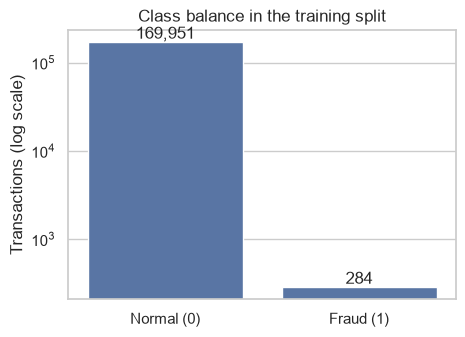

In [3]:
counts = train[config.TARGET].value_counts().sort_index()
share = counts / counts.sum()
print(pd.DataFrame({"count": counts, "share %": (share * 100).round(3)}))
print(f"Imbalance ratio: 1 fraud for every {counts[0] / counts[1]:.0f} normal transactions")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["Normal (0)", "Fraud (1)"], y=counts.values, ax=ax)
ax.set_yscale("log")
ax.set_ylabel("Transactions (log scale)")
ax.set_title("Class balance in the training split")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
save(fig, "eda_class_balance")
plt.show()

## 3. Transaction amount

          count    mean     std  min  25%    50%     75%       max
Class                                                             
0      169951.0   88.11  246.43  0.0  5.7  22.05   77.50  19656.53
1         284.0  118.87  254.12  0.0  1.0  11.86  104.22   2125.87


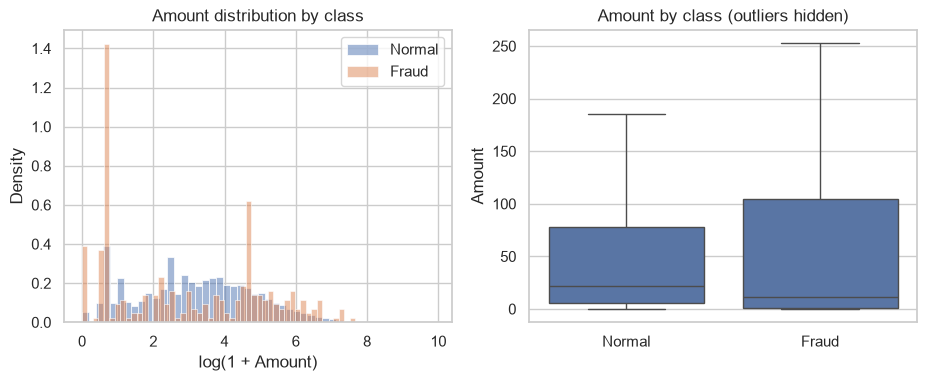

In [4]:
print(train.groupby(config.TARGET)["Amount"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for cls, label in [(0, "Normal"), (1, "Fraud")]:
    sns.histplot(np.log1p(train.loc[train.Class == cls, "Amount"]), bins=50,
                 stat="density", ax=axes[0], label=label, alpha=0.5)
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_title("Amount distribution by class")
axes[0].legend()
sns.boxplot(data=train, x=config.TARGET, y="Amount", ax=axes[1], showfliers=False)
axes[1].set_xticks([0, 1], ["Normal", "Fraud"])
axes[1].set_xlabel("")
axes[1].set_title("Amount by class (outliers hidden)")
save(fig, "eda_amount")
plt.show()

## 4. Time and hour of day

`Time` is seconds since the first transaction, over two days. Hour of day is `(Time // 3600) % 24`. The real clock time is not given, so hour 0 is only the start of the recording.

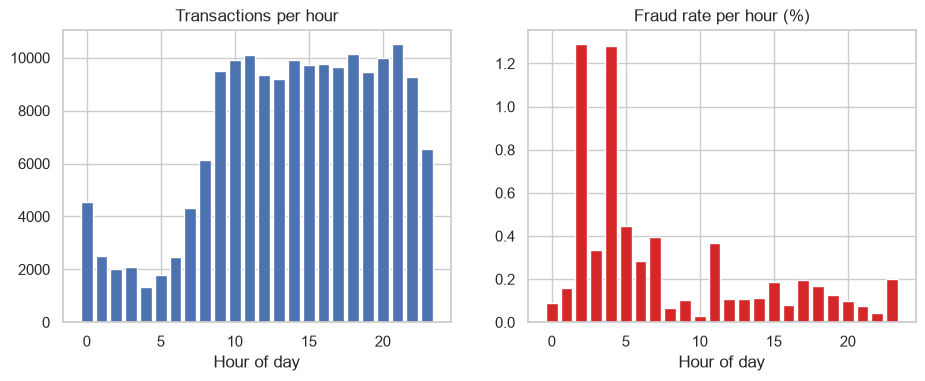

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
count,4535.000,2501.00,2012.000,2077.000,1325.000,1785.000,2472.000,4308.000,6153.000,9506.000,...,9910.000,9744.000,9754.000,9637.000,10151.000,9465.000,9979.0,10535.000,9258.000,6542.000
fraud_pct,0.088,0.16,1.292,0.337,1.283,0.448,0.283,0.395,0.065,0.105,...,0.111,0.185,0.082,0.197,0.167,0.127,0.1,0.076,0.043,0.199


In [5]:
hour = (train["Time"] // 3600 % 24).astype(int)
by_hour = pd.DataFrame({"hour": hour, "Class": train[config.TARGET]})
rate = by_hour.groupby("hour")["Class"].agg(["count", "mean"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(rate.index, rate["count"])
axes[0].set_title("Transactions per hour")
axes[0].set_xlabel("Hour of day")
axes[1].bar(rate.index, rate["mean"] * 100, color="tab:red")
axes[1].set_title("Fraud rate per hour (%)")
axes[1].set_xlabel("Hour of day")
save(fig, "eda_hour_of_day")
plt.show()
rate.assign(fraud_pct=(rate["mean"] * 100).round(3)).drop(columns="mean").T

## 5. Correlation with the target

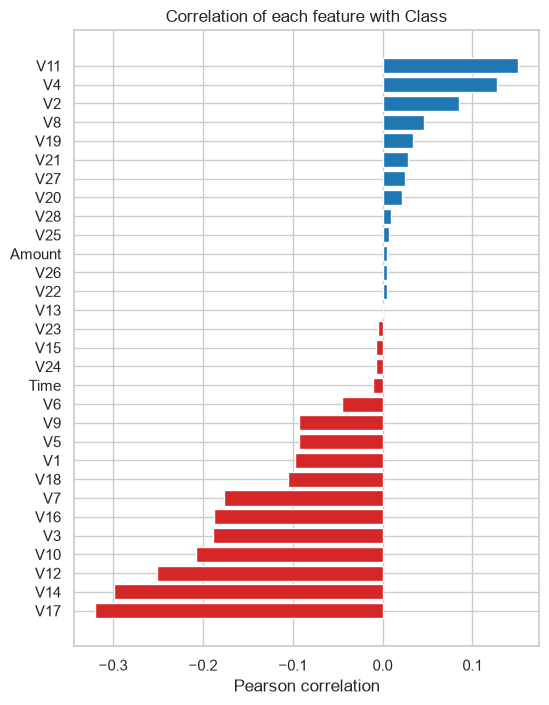

Strongest negative: {'V17': -0.32, 'V14': -0.299, 'V12': -0.251, 'V10': -0.208, 'V3': -0.189}
Strongest positive: {'V19': 0.034, 'V8': 0.046, 'V2': 0.085, 'V4': 0.127, 'V11': 0.151}


In [6]:
corr = train.corr(numeric_only=True)[config.TARGET].drop(config.TARGET).sort_values()

fig, ax = plt.subplots(figsize=(6, 8))
colors = ["tab:red" if v < 0 else "tab:blue" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors)
ax.set_title("Correlation of each feature with Class")
ax.set_xlabel("Pearson correlation")
save(fig, "eda_correlation_with_class")
plt.show()

print("Strongest negative:", corr.head(5).round(3).to_dict())
print("Strongest positive:", corr.tail(5).round(3).to_dict())

## 6. Distributions of the most useful features

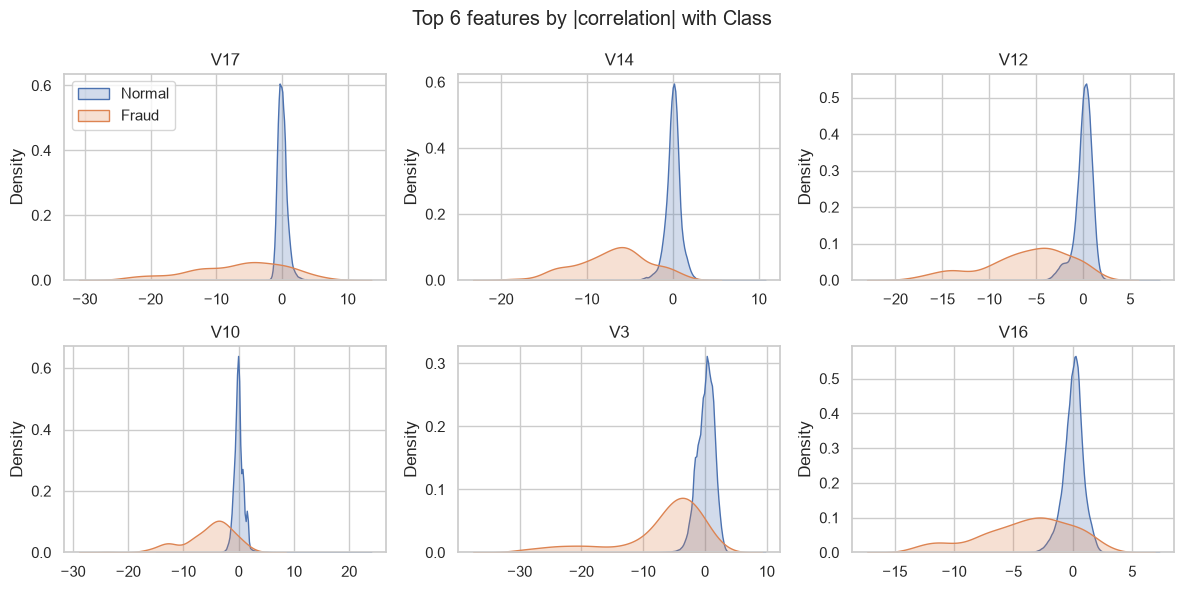

In [7]:
top = corr.abs().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), top):
    for cls, label in [(0, "Normal"), (1, "Fraud")]:
        sns.kdeplot(train.loc[train.Class == cls, col], ax=ax, label=label,
                    fill=True, common_norm=False, warn_singular=False)
    ax.set_title(col)
    ax.set_xlabel("")
axes[0, 0].legend()
fig.suptitle("Top 6 features by |correlation| with Class")
fig.tight_layout()
save(fig, "eda_top_features_kde")
plt.show()

## 7. Correlation between features

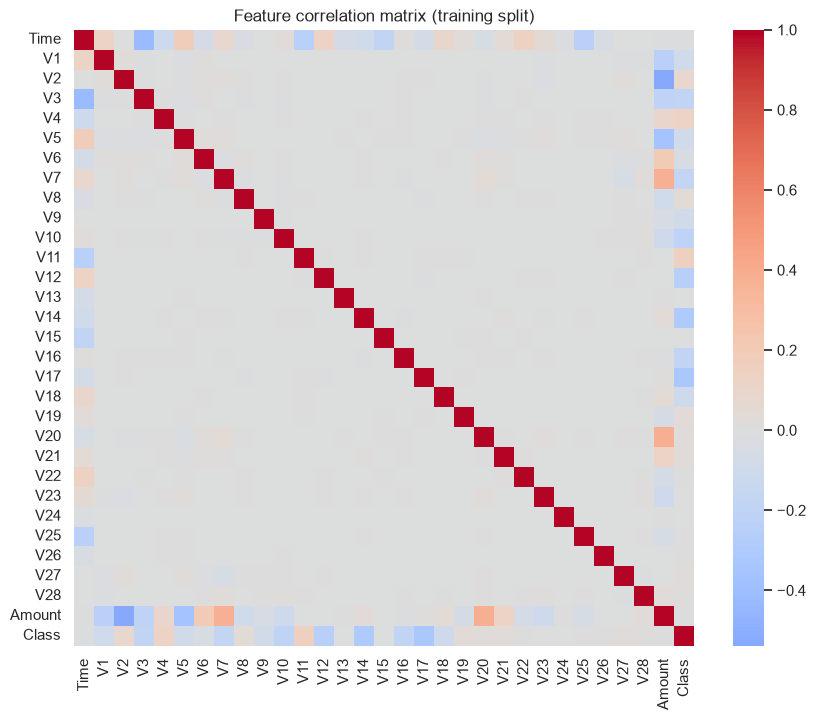

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(train.corr(numeric_only=True), cmap="coolwarm", center=0, ax=ax,
            xticklabels=True, yticklabels=True)
ax.set_title("Feature correlation matrix (training split)")
save(fig, "eda_correlation_matrix")
plt.show()

## 8. Observations

1. **Extreme imbalance.** Only 284 of 170,235 training rows are fraud (0.167%), about 1 fraud for every 598 normal transactions. Accuracy is useless here, so I will use precision, recall, F1 and PR-AUC.
2. **Amount.** Fraud amounts have a lower median (11.86 vs 22.05) but a higher mean (118.87 vs 88.11), so fraud is a mix of very small "test" payments and some large ones. Amount is very skewed with big outliers (max 19,656), which supports using RobustScaler.
3. **Hour of day.** Most normal transactions happen in hours 8–23. In the night hours (around 2–4) there are few transactions but the fraud rate is much higher (about 1.3% at hours 2 and 4, against about 0.1% in the day). This supports adding an hour-of-day feature.
4. **PCA features.** V17, V14, V12, V10 and V3 have the strongest (negative) correlation with Class. For fraud, these features have much wider distributions shifted to negative values, while normal transactions stay close to 0. This also suggests that fraud looks like an outlier, which is a good sign for Isolation Forest.
5. **Feature correlation.** V1–V28 are almost uncorrelated with each other, as expected after PCA. Only Time and Amount show some correlation with a few V features. So multicollinearity is not a big problem for Logistic Regression.
6. **Limits.** The features are anonymised, so I cannot explain them by name, and "hour 0" is only the start of the recording, not midnight.